# Week 10: Learning Curves and More Training Techniques

In this notebook, we extend our neural-network workflow beyond simply fitting a model. Using the MNIST dataset, we will examine how training progresses over time and explore several techniques for improving model performance and generalization.

We will begin with **learning curves**, comparing training and validation loss and accuracy to identify underfitting, good fit, and overfitting. We will then experiment with several techniques commonly used in deep learning, including:

- **Early stopping**
- **Weight initialization**
- **Activation functions**
- **Batch normalization**
- **L2 regularization**
- **Dropout**
- **Deeper network architectures**
- **Learning-rate schedules**

As in earlier modules, we will use separate **training, validation, and test sets**. The validation set will be used to compare models and make design choices, while the test set will remain untouched until the final model has been selected.

At the end of the notebook, we will combine several of these techniques into a final network, retrain the selected design on the complete **development set (Train + Validation)**, and evaluate it once on the test set.

## 1. Setup and Data Loading
Import necessary libraries and preprocess the MNIST dataset.

In [1]:
# Imports and global variables

import math
import numpy as np
import os
import time
import matplotlib.pyplot as plt

from tqdm.notebook import tqdm
from collections import Counter

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

import tensorflow as tf

# Disable GPU / Apple Metal
tf.config.set_visible_devices([], "GPU")

print("Visible devices:", tf.config.get_visible_devices())

from tensorflow import keras
from tensorflow.keras import models, layers, regularizers, callbacks
from tensorflow.keras.callbacks import Callback,EarlyStopping,ReduceLROnPlateau,LearningRateScheduler
from tensorflow.keras.layers import Input, Dense, ReLU, BatchNormalization, Dropout, LeakyReLU
from tensorflow.keras.models import Sequential
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.optimizers.schedules import ExponentialDecay, CosineDecay, PiecewiseConstantDecay


# utility code

def format_hms(seconds):
    return time.strftime("%H:%M:%S", time.gmtime(seconds))

os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'  # Suppresses INFO and WARNING messages

Visible devices: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


In [2]:
# Utility to record results by title of experiment

results = {}

def print_results():

    print(f"{'Model':<40} {'Val Acc':>10} {'Val Loss':>10} {'Best Epoch':>12} {'Epochs Run':>12}")
    print("-" * 90)

    for title, r in sorted(
        results.items(),
        key=lambda kv: kv[1]["val_accuracy"],
        reverse=True
    ):
        print(
            f"{title:<40} "
            f"{r['val_accuracy']:>10.4f} "
            f"{r['val_loss']:>10.4f} "
            f"{r['best_epoch']:>12} "
            f"{r['epochs_run']:>12}"
        )

In [3]:
# Utility to print learning curves

def plot_learning_curves(hist, 
                         title="Learning Curves", 
                         best_epoch=None,              # None = print absolute minimum val_loss point on both plots
                                                       # else assume is 0-based early stopping trigger point
                         verbose=True
                        ):

    val_losses = hist.history['val_loss']
    
    if best_epoch is not None:
        min_val_epoch = best_epoch
    else:
        min_val_epoch = val_losses.index(min(val_losses))
        
    val_loss_at_min_loss = hist.history['val_loss'][min_val_epoch]    
    val_acc_at_min_loss = hist.history['val_accuracy'][min_val_epoch]
    

    n_epochs = len(val_losses)
    epochs = list(range(1, n_epochs + 1))

    # Determine tick interval and xticks starting from 0

    tick_interval = max(1, n_epochs // 20)
    xticks = list(range(0, n_epochs + 1, tick_interval))

    plt.figure(figsize=(8, 8))

    # --- Loss Plot ---
    plt.subplot(2, 1, 1)
    plt.plot(epochs, hist.history['loss'], label='Train Loss')
    plt.plot(epochs, hist.history['val_loss'], label='Val Loss')
    plt.scatter(min_val_epoch + 1, val_loss_at_min_loss, color='red', marker='x', s=50, label='Min Val Loss') 
    plt.title(f'{title} - Loss')
    plt.ylabel('Loss')
    plt.xticks(xticks)
    plt.legend()
    plt.grid(True)

    # --- Accuracy Plot ---
    plt.subplot(2, 1, 2)
    plt.plot(epochs, hist.history['accuracy'], label='Train Accuracy')
    plt.plot(epochs, hist.history['val_accuracy'], label='Val Accuracy')
    plt.scatter(min_val_epoch + 1, val_acc_at_min_loss, color='red', marker='x', s=50, label='Acc @ Min Val Loss')
    plt.title(f'{title} - Accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    # plt.ylim(0, 1.05)
    plt.xticks(xticks)
    plt.legend()
    plt.grid(True)

    plt.tight_layout()
    plt.show()

    if verbose:
        print(f"Final Training Loss:            {hist.history['loss'][-1]:.4f}")
        print(f"Final Training Accuracy:        {hist.history['accuracy'][-1]:.4f}")
        print(f"Final Validation Loss:          {hist.history['val_loss'][-1]:.4f}")
        print(f"Final Validation Accuracy:      {hist.history['val_accuracy'][-1]:.4f}")
        print(f"Minimum Validation Loss:        {val_loss_at_min_loss:.4f} (Epoch {min_val_epoch + 1})")
        print(f"Validation Accuracy @ Min Loss: {val_acc_at_min_loss:.4f}")


In [4]:
# Globals

epochs = 100
batch_size = 128
learning_rate = 1e-3     # Adam default
baseline_width = 1024

# Assumes X_train, y_train, X_val, y_val defined as globals before call

def train_and_validate(model,
                       epochs              = epochs,
                       learning_rate       = learning_rate,
                       optimizer           = "Adam",
                       title               = "Learning Curves",
                       batch_size          = batch_size,
                       use_early_stopping  = True,
                       patience            = 6,
                       min_delta           = 0.0001,
                       extra_callbacks     = None,
                       verbose             = 0,
                       return_history      = False
                      ):

    if extra_callbacks is None:
        extra_callbacks = []

    print(f"\n{title}")

    # --------------------------------------------------
    # Optimizer
    # --------------------------------------------------

    if optimizer == "Adam":
        opt = Adam(learning_rate=learning_rate)
    else:
        opt = optimizer

    # Compile here, in one place.
    model.compile(
        optimizer=opt,
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    # --------------------------------------------------
    # Callbacks
    # --------------------------------------------------

    callbacks_list = list(extra_callbacks)

    early_stop = None

    if use_early_stopping:

        early_stop = EarlyStopping(
            monitor="val_loss",
            patience=patience,
            min_delta=min_delta,
            restore_best_weights=True,
            verbose=verbose
        )

        callbacks_list.insert(0, early_stop)

    # --------------------------------------------------
    # Train
    #
    # IMPORTANT:
    # X_val and y_val are a fixed validation set created
    # once before these experiments begin.
    #
    # The test set is NOT used here.
    # --------------------------------------------------

    start = time.time()

    history = model.fit(
        X_train,
        y_train,
        epochs=epochs,
        batch_size=batch_size,
        validation_data=(X_val, y_val),
        callbacks=callbacks_list,
        verbose=verbose
    )

    end = time.time()

    # --------------------------------------------------
    # Identify best validation epoch
    # --------------------------------------------------

    val_losses = history.history["val_loss"]

    if use_early_stopping:
        # This is the epoch whose weights Keras restored.
        best_epoch = early_stop.best_epoch
    else:
        # For reporting only. Without early stopping,
        # the model itself still has the final epoch's weights.
        best_epoch = int(np.argmin(val_losses))

    best_val_loss = history.history["val_loss"][best_epoch]
    best_val_acc  = history.history["val_accuracy"][best_epoch]

    epochs_run = len(history.history["loss"])

    # --------------------------------------------------
    # Plot learning curves
    # --------------------------------------------------

    plot_learning_curves(
        history,
        title=title,
        best_epoch=best_epoch
    )

    # --------------------------------------------------
    # Summary
    # --------------------------------------------------

    print(f"\nEpochs trained:                 {epochs_run}")
    print(f"Best validation epoch:          {best_epoch + 1}")
    print(f"Best validation loss:           {best_val_loss:.4f}")
    print(f"Validation accuracy at best:    {best_val_acc:.4f}")

    if use_early_stopping:
        print(
            f"Model weights restored from:    "
            f"epoch {best_epoch + 1}"
        )
    else:
        print(
            f"Model weights retained from:    "
            f"final epoch {epochs_run}"
        )

    print(f"Execution time:                 {format_hms(end - start)}")

    # Save results for later comparison.
    results[title] = {
        "val_loss": best_val_loss,
        "val_accuracy": best_val_acc,
        "best_epoch": best_epoch + 1,
        "epochs_run": epochs_run
    }

    if return_history:
        return history

### Preparing MNIST for the Network

We will again use the **MNIST** dataset of handwritten digits. Because our network uses `Dense` layers, each $28\times28$ image must first be reshaped into a one-dimensional vector of 784 pixel values.

```python
X_train = X_train.reshape(-1, 784)
X_test  = X_test.reshape(-1, 784)
```

The original pixel values range from 0 to 255. We also **rescale** them to the range $[0,1]$:

```python
X_train = X_train.astype("float32") / 255.0
X_test  = X_test.astype("float32") / 255.0
```

Rescaling places all input features on a consistent numerical scale, which generally makes neural network optimization more stable and efficient. Because the original pixel range is known in advance, dividing by 255 provides a simple and natural transformation for MNIST.

> **Note:** Flattening is needed here because we are using fully connected Dense layers. Convolutional Neural Networks can preserve the two-dimensional structure of the images.


In [5]:
# Load MNIST
(X_development, y_development), (X_test, y_test) = tf.keras.datasets.mnist.load_data()

# Flatten and rescale images
X_development = X_development.reshape(-1, 784).astype("float32") / 255.0
X_test        = X_test.reshape(-1, 784).astype("float32") / 255.0

num_classes = 10

# Split the development set into fixed training and validation sets
X_train, X_val, y_train, y_val = train_test_split(
    X_development,
    y_development,
    test_size=0.20,
    random_state=42,
    stratify=y_development
)

print("Development set:", X_development.shape, y_development.shape)
print("Training set:   ", X_train.shape, y_train.shape)
print("Validation set: ", X_val.shape, y_val.shape)
print("Test set:       ", X_test.shape, y_test.shape)

Development set: (60000, 784) (60000,)
Training set:    (48000, 784) (48000,)
Validation set:  (12000, 784) (12000,)
Test set:        (10000, 784) (10000,)


Let's look at a few images to get a feel for the dataset....

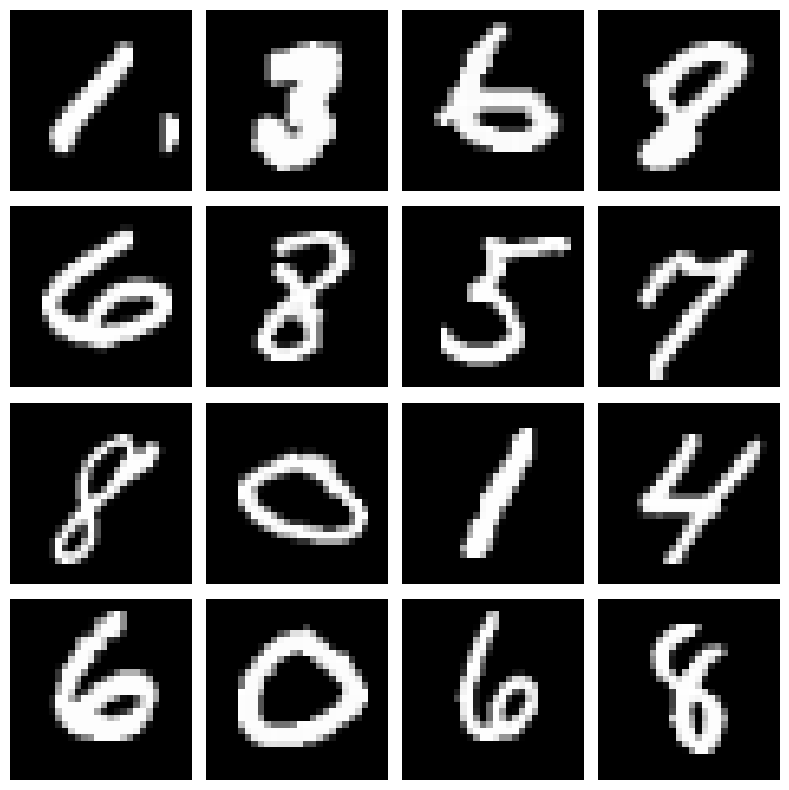

In [6]:
# Display a 4x4 grid of MNIST images without labels

fig, axes = plt.subplots(4, 4, figsize=(8, 8))
axes = axes.flatten()

for i, ax in enumerate(axes):
    ax.imshow(X_train[i].reshape(28, 28), cmap="gray")
    ax.axis("off")

plt.tight_layout()
plt.show()


## 2. Baseline Model 
We'll define a simple model and plot learning curves (training vs validation loss & accuracy).


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 1024)           │       803,840 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │        10,250 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 814,090 (3.11 MB)

 Trainable params: 814,090 (3.11 MB)

 Non-trainable params: 0 (0.00 B)

None


Baseline Model


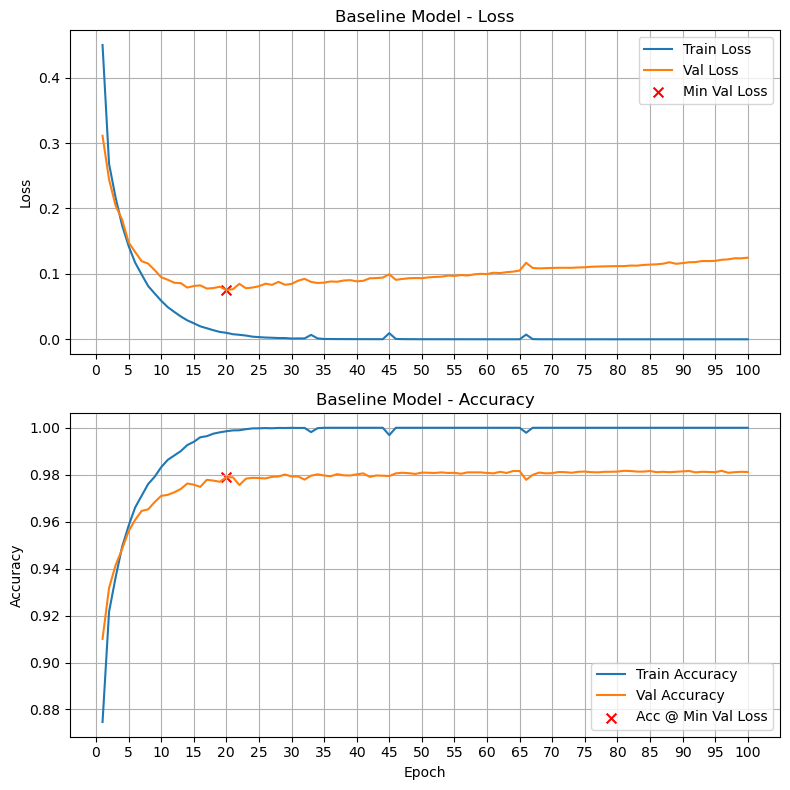

Final Training Loss:            0.0000
Final Training Accuracy:        1.0000
Final Validation Loss:          0.1248
Final Validation Accuracy:      0.9812
Minimum Validation Loss:        0.0753 (Epoch 20)
Validation Accuracy @ Min Loss: 0.9789

Epochs trained:                 100
Best validation epoch:          20
Best validation loss:           0.0753
Validation accuracy at best:    0.9789
Model weights retained from:    final epoch 100
Execution time:                 00:02:40


In [7]:
base_model = models.Sequential([
    Input(shape=(X_train.shape[1],)),
    Dense(
        baseline_width,
        activation="sigmoid",
        kernel_initializer="glorot_uniform"
    ),
    Dense(
        num_classes,
        activation="softmax"
    )
])

display(base_model.summary())

train_and_validate(
    base_model,
    title="Baseline Model",
    use_early_stopping=False,
    verbose=0
)

## 3. Early Stopping Using Callbacks

Early stopping is a technique for stopping training when validation performance stops improving. In Keras, it is implemented using a **callback**.

> In Keras, a **callback** is an object that can monitor or modify training at specific stages, such as after each epoch. Callbacks can be used for tasks such as early stopping, saving model checkpoints, or adjusting the learning rate.

See the **Appendix** for a summary of useful callbacks in Keras. 

### Early Stopping

Early stopping monitors a quantity such as validation loss and halts training if it does not improve sufficiently for a specified number of epochs.

A typical definition, which we use in our `train_and_validate` function, is:

```python
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    min_delta=0.0001,
    restore_best_weights=True,
    verbose=0
)
```

The important parameters are:

- **`monitor`**: The quantity to watch. Here we monitor validation loss.
- **`patience`**: The number of epochs to wait without sufficient improvement before stopping.
- **`min_delta`**: The minimum improvement required to reset the patience counter.
- **`restore_best_weights=True`**: After training stops, restore the model weights from the epoch with the best monitored validation performance.

This last point is important. The model at the end of the patience period is not necessarily the best model. If we monitor `val_loss`, Keras restores the weights from the epoch with the **lowest validation loss**.

### Why Monitor Validation Loss?

Validation loss is commonly used for early stopping because:

- It is directly related to the objective being minimized during training.
- It is usually more sensitive to small changes in model performance than accuracy.
- Accuracy can remain unchanged even while the model's predicted probabilities improve or worsen.
- An increase in validation loss can provide an early indication of overfitting.

### Choosing `patience`

Validation loss does not always improve smoothly from one epoch to the next. A small amount of **patience** allows training to continue through temporary fluctuations.

If patience is too small, training may stop prematurely. If it is too large, training may continue unnecessarily after validation performance has stopped improving.

> **Early stopping uses validation performance to decide when training should stop and, with `restore_best_weights=True`, which model weights should be retained.**

From this point forward, we will normally use early stopping when training our experimental models.


Baseline Model -- With Early Stopping


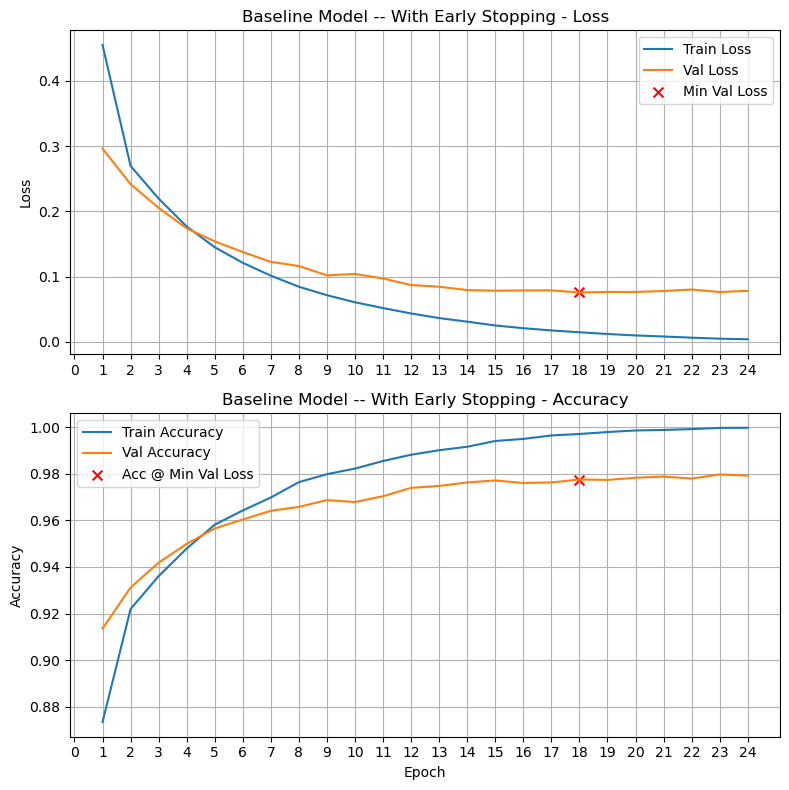

Final Training Loss:            0.0041
Final Training Accuracy:        0.9997
Final Validation Loss:          0.0783
Final Validation Accuracy:      0.9792
Minimum Validation Loss:        0.0759 (Epoch 18)
Validation Accuracy @ Min Loss: 0.9775

Epochs trained:                 24
Best validation epoch:          18
Best validation loss:           0.0759
Validation accuracy at best:    0.9775
Model weights restored from:    epoch 18
Execution time:                 00:00:41


In [8]:
base_model_es = models.Sequential([
    Input(shape=(X_train.shape[1],)),
    Dense(
        baseline_width,
        activation="sigmoid",
        kernel_initializer="glorot_uniform"
    ),
    Dense(
        num_classes,
        activation="softmax"
    )
])

train_and_validate(
    base_model_es,
    title="Baseline Model -- With Early Stopping",
    verbose=0
)

## 4. Activations 

We'll try all three of the common activation functions with the MNIST dataset:

- Baseline with sigmoid    (ha, already done above!)
- Baseline with tanh
- Baseline with ReLU 

The default Keras initialization is `glorot_uniform`, which works well with `sigmoid` and `tanh`. For ReLU layers, a He initializer such as `he_uniform` is generally more appropriate.


Baseline Model -- Tanh


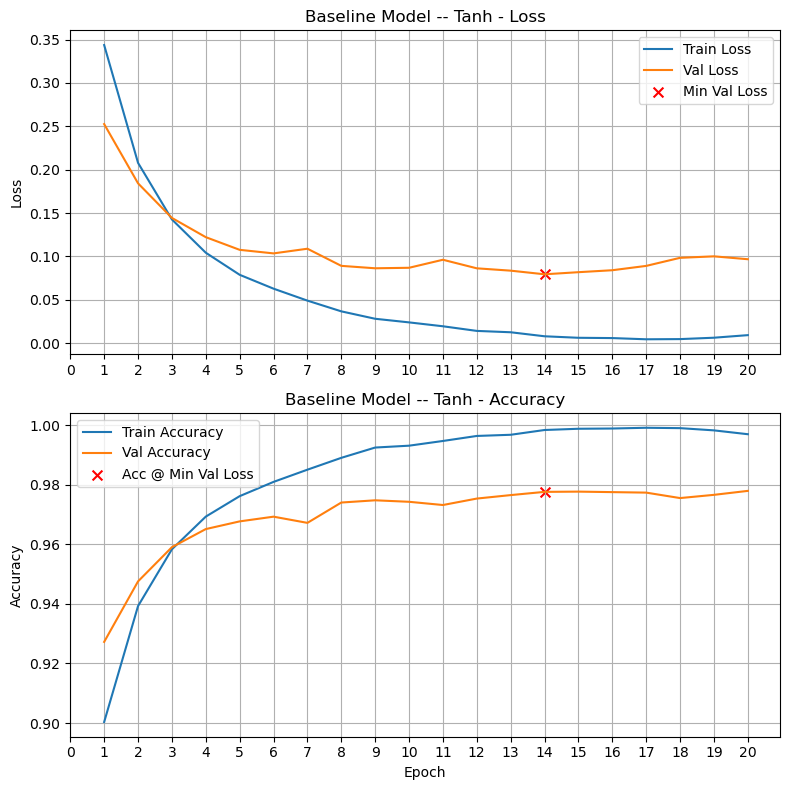

Final Training Loss:            0.0092
Final Training Accuracy:        0.9970
Final Validation Loss:          0.0967
Final Validation Accuracy:      0.9780
Minimum Validation Loss:        0.0794 (Epoch 14)
Validation Accuracy @ Min Loss: 0.9777

Epochs trained:                 20
Best validation epoch:          14
Best validation loss:           0.0794
Validation accuracy at best:    0.9777
Model weights restored from:    epoch 14
Execution time:                 00:00:36


In [9]:
base_model_tanh = models.Sequential([
    Input(shape=(X_train.shape[1],)),
    Dense(
        baseline_width,
        activation="tanh",
        kernel_initializer="glorot_uniform"            # default
    ),
    Dense(
        num_classes,
        activation="softmax"
    )
])

train_and_validate(
    base_model_tanh,
    title="Baseline Model -- Tanh",
    verbose=0
)


Baseline Model -- ReLU


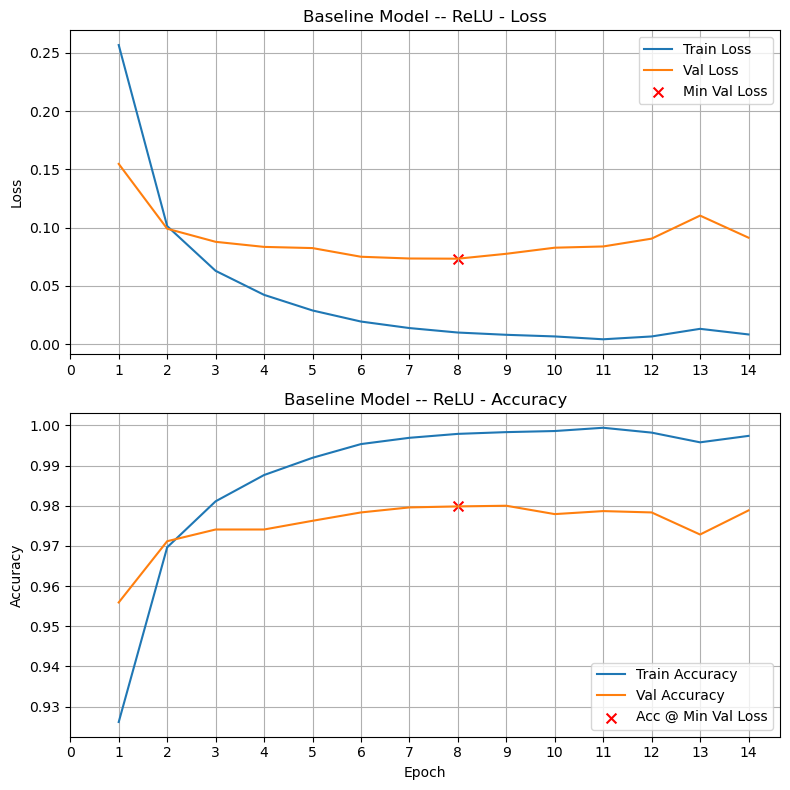

Final Training Loss:            0.0083
Final Training Accuracy:        0.9974
Final Validation Loss:          0.0913
Final Validation Accuracy:      0.9788
Minimum Validation Loss:        0.0733 (Epoch 8)
Validation Accuracy @ Min Loss: 0.9798

Epochs trained:                 14
Best validation epoch:          8
Best validation loss:           0.0733
Validation accuracy at best:    0.9798
Model weights restored from:    epoch 8
Execution time:                 00:00:27


In [10]:
base_model_relu = models.Sequential([
    Input(shape=(X_train.shape[1],)),
    Dense(
        baseline_width,
        activation="relu",
        kernel_initializer="he_uniform"    
    ),
    Dense(
        num_classes,
        activation="softmax"
    )
])

train_and_validate(
    base_model_relu,
    title="Baseline Model -- ReLU",
    verbose=0
)

## 5. Batch Normalization

Using the `relu` version of the baseline model, we will try adding batch normalization to
the hidden layer. 

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_8 (Dense)                 │ (None, 1024)           │       803,840 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1024)           │         4,096 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 10)             │        10,250 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 818,186 (3.12 MB)

 Trainable params: 816,138 (3.11 MB)

 Non-trainable params: 2,048 (8.00 KB)

None


Batch Normalization


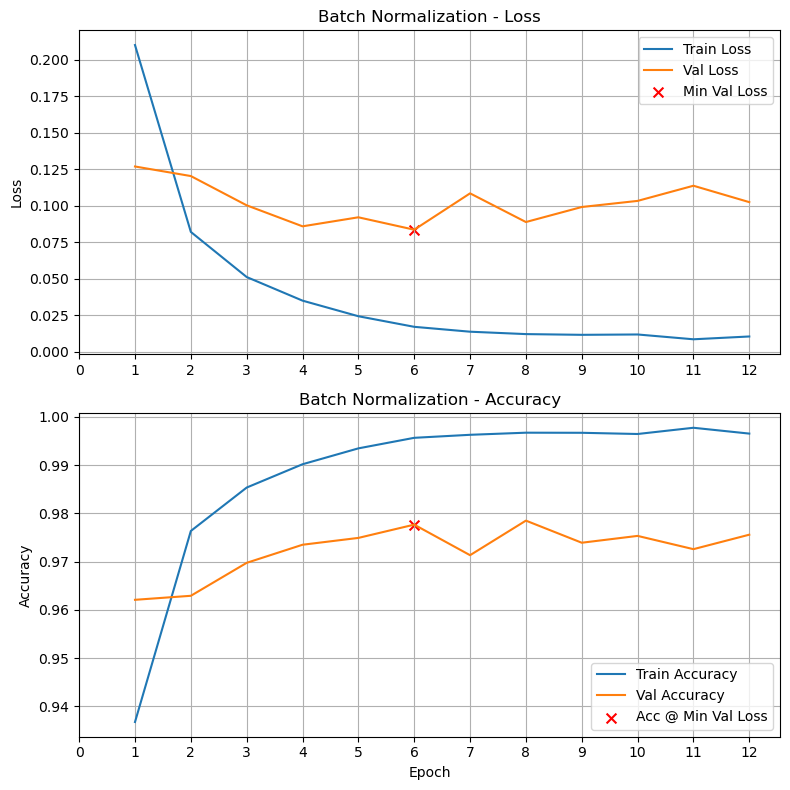

Final Training Loss:            0.0105
Final Training Accuracy:        0.9965
Final Validation Loss:          0.1025
Final Validation Accuracy:      0.9756
Minimum Validation Loss:        0.0836 (Epoch 6)
Validation Accuracy @ Min Loss: 0.9777

Epochs trained:                 12
Best validation epoch:          6
Best validation loss:           0.0836
Validation accuracy at best:    0.9777
Model weights restored from:    epoch 6
Execution time:                 00:00:28


In [11]:
batchnorm_model = models.Sequential([
    Input(shape=(X_train.shape[1],)),

    Dense(
        baseline_width,
        activation=None,
        kernel_initializer="he_uniform"
    ),
    BatchNormalization(),
    ReLU(),
    Dense(
        num_classes,
        activation="softmax"
    )
])

display(batchnorm_model.summary())

train_and_validate(
    batchnorm_model,
    title="Batch Normalization",
    verbose=0
)

## 6. Regularization:  L2 and Dropout

We'll try three experiments with the MNIST dataset:

- Baseline plus L2 Regularization
- Baseline plus Dropout
- Baseline with Both

### L2 Regularization


ReLU + L2 Regularization  1e-05


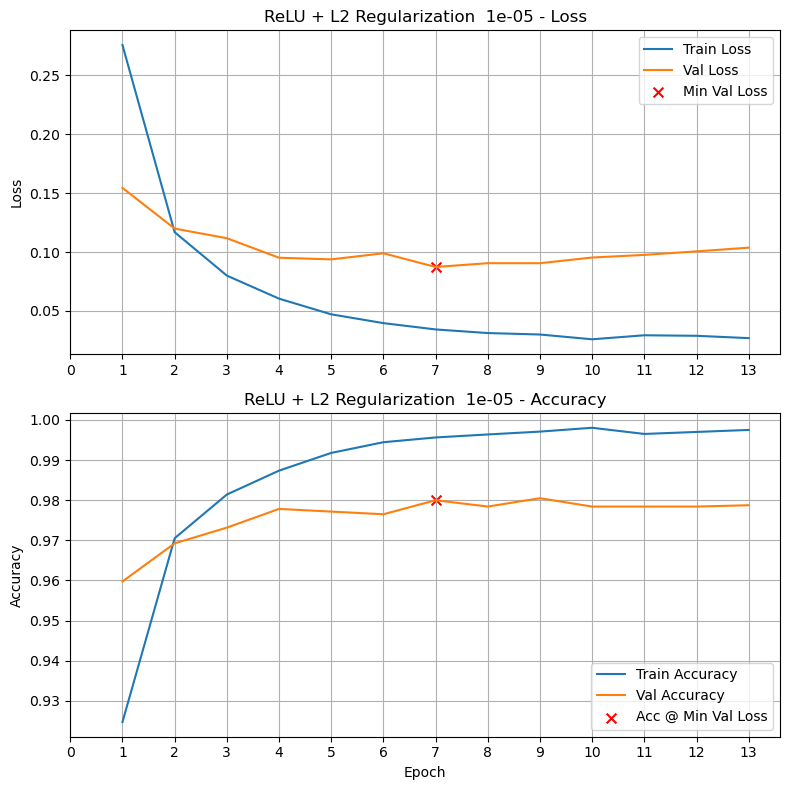

Final Training Loss:            0.0269
Final Training Accuracy:        0.9975
Final Validation Loss:          0.1038
Final Validation Accuracy:      0.9787
Minimum Validation Loss:        0.0874 (Epoch 7)
Validation Accuracy @ Min Loss: 0.9800

Epochs trained:                 13
Best validation epoch:          7
Best validation loss:           0.0874
Validation accuracy at best:    0.9800
Model weights restored from:    epoch 7
Execution time:                 00:00:27


In [12]:
l2 = 1e-5

l2_model = models.Sequential([
    Input(shape=(X_train.shape[1],)),
    Dense(
        baseline_width,
        activation="relu",
        kernel_initializer="he_uniform",
        kernel_regularizer=regularizers.l2(l2)
    ),
    Dense(
        num_classes,
        activation="softmax"
    )
])

train_and_validate(
    l2_model,
    title=f"ReLU + L2 Regularization  {l2}",
    verbose=0
)

### Dropout



ReLU + Dropout 0.3


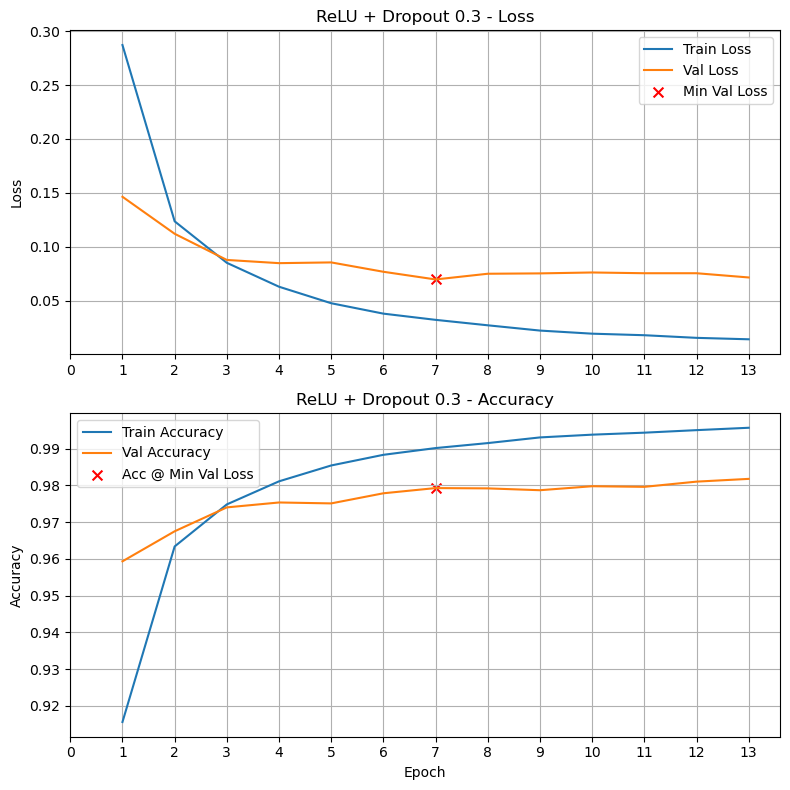

Final Training Loss:            0.0141
Final Training Accuracy:        0.9956
Final Validation Loss:          0.0715
Final Validation Accuracy:      0.9818
Minimum Validation Loss:        0.0697 (Epoch 7)
Validation Accuracy @ Min Loss: 0.9793

Epochs trained:                 13
Best validation epoch:          7
Best validation loss:           0.0697
Validation accuracy at best:    0.9793
Model weights restored from:    epoch 7
Execution time:                 00:00:27


In [13]:
do = 0.3
DO_model = models.Sequential([
    Input(shape=(X_train.shape[1],)),
    Dense(
        baseline_width,
        activation="relu",
        kernel_initializer="he_uniform",
    ),
    Dropout(do),
    Dense(
        num_classes,
        activation="softmax"
    ),
    
])

train_and_validate(
    DO_model,
    title=f"ReLU + Dropout {do}",
    verbose=0
)

### L2 Regularization and Dropout


Baseline Model -- L2 1e-05 & DO 0.3


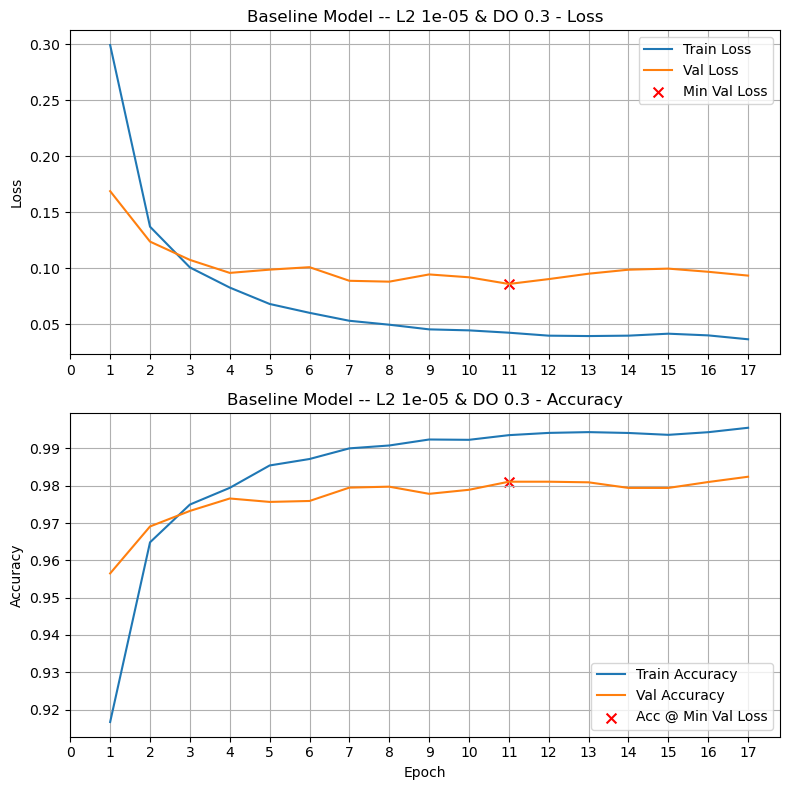

Final Training Loss:            0.0365
Final Training Accuracy:        0.9955
Final Validation Loss:          0.0933
Final Validation Accuracy:      0.9824
Minimum Validation Loss:        0.0859 (Epoch 11)
Validation Accuracy @ Min Loss: 0.9811

Epochs trained:                 17
Best validation epoch:          11
Best validation loss:           0.0859
Validation accuracy at best:    0.9811
Model weights restored from:    epoch 11
Execution time:                 00:00:38


In [14]:
l2 = 1e-5
do = 0.3

base_model_l2_do = models.Sequential([
    Input(shape=(X_train.shape[1],)),
    Dense(
        baseline_width,
        activation="relu",
        kernel_initializer="he_uniform",
        kernel_regularizer=regularizers.l2(l2)
    ),
    Dropout(do),
    Dense(
        num_classes,
        activation="softmax"
    )
])

train_and_validate(
    base_model_l2_do,
    title=f"Baseline Model -- L2 {l2} & DO {do}",
    verbose=0
)

## 7. Exploring Architectures

### 7.1. Does Wider Mean Better?


Baseline Model Wider: 16


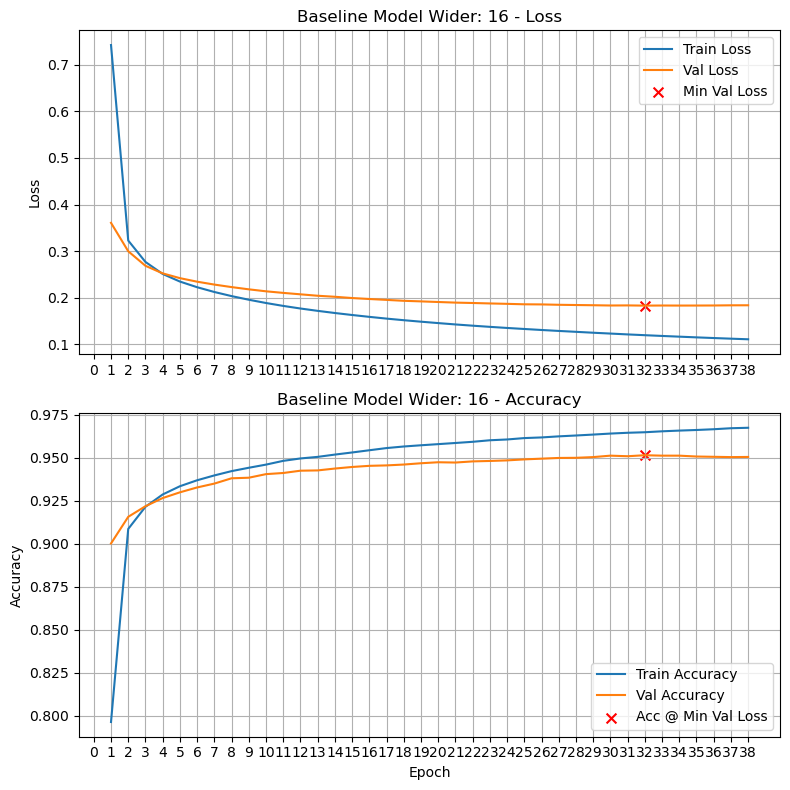

Final Training Loss:            0.1107
Final Training Accuracy:        0.9676
Final Validation Loss:          0.1838
Final Validation Accuracy:      0.9506
Minimum Validation Loss:        0.1830 (Epoch 32)
Validation Accuracy @ Min Loss: 0.9516

Epochs trained:                 38
Best validation epoch:          32
Best validation loss:           0.1830
Validation accuracy at best:    0.9516
Model weights restored from:    epoch 32
Execution time:                 00:00:09

Baseline Model Wider: 32


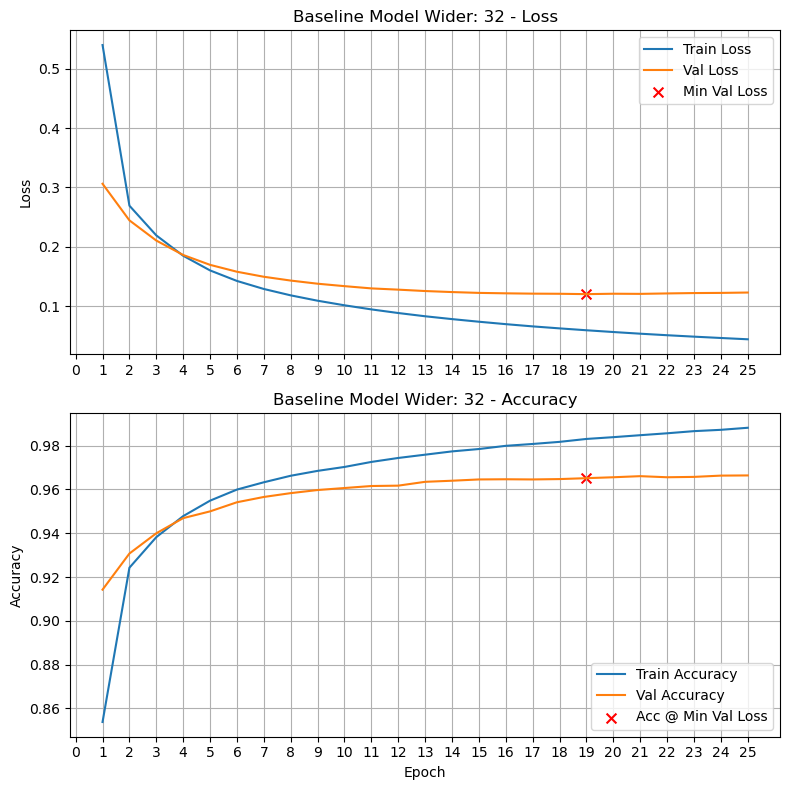

Final Training Loss:            0.0441
Final Training Accuracy:        0.9882
Final Validation Loss:          0.1229
Final Validation Accuracy:      0.9664
Minimum Validation Loss:        0.1202 (Epoch 19)
Validation Accuracy @ Min Loss: 0.9652

Epochs trained:                 25
Best validation epoch:          19
Best validation loss:           0.1202
Validation accuracy at best:    0.9652
Model weights restored from:    epoch 19
Execution time:                 00:00:07

Baseline Model Wider: 64


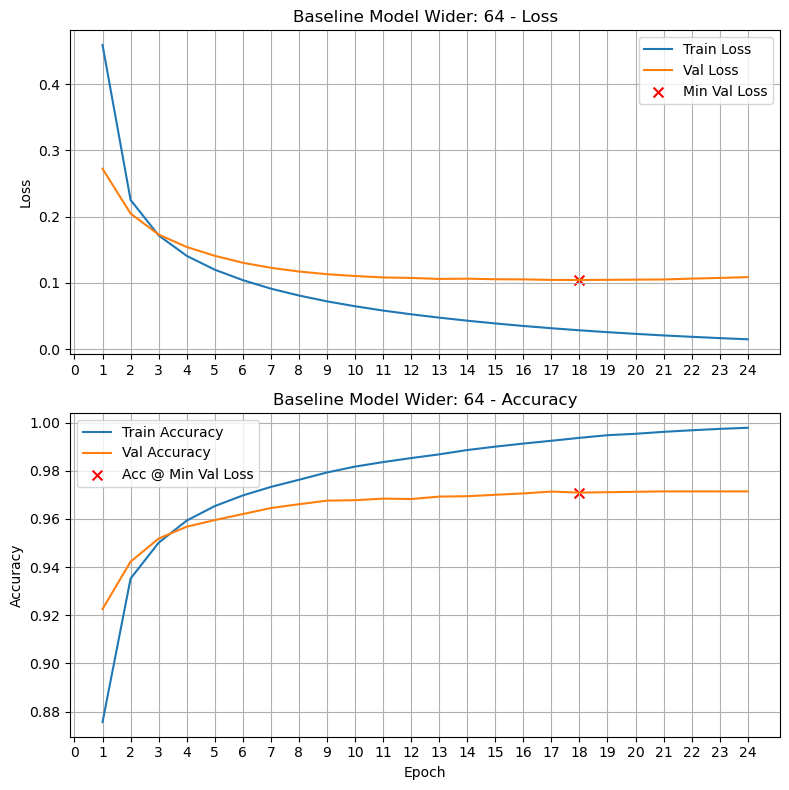

Final Training Loss:            0.0147
Final Training Accuracy:        0.9978
Final Validation Loss:          0.1086
Final Validation Accuracy:      0.9714
Minimum Validation Loss:        0.1043 (Epoch 18)
Validation Accuracy @ Min Loss: 0.9709

Epochs trained:                 24
Best validation epoch:          18
Best validation loss:           0.1043
Validation accuracy at best:    0.9709
Model weights restored from:    epoch 18
Execution time:                 00:00:10

Baseline Model Wider: 128


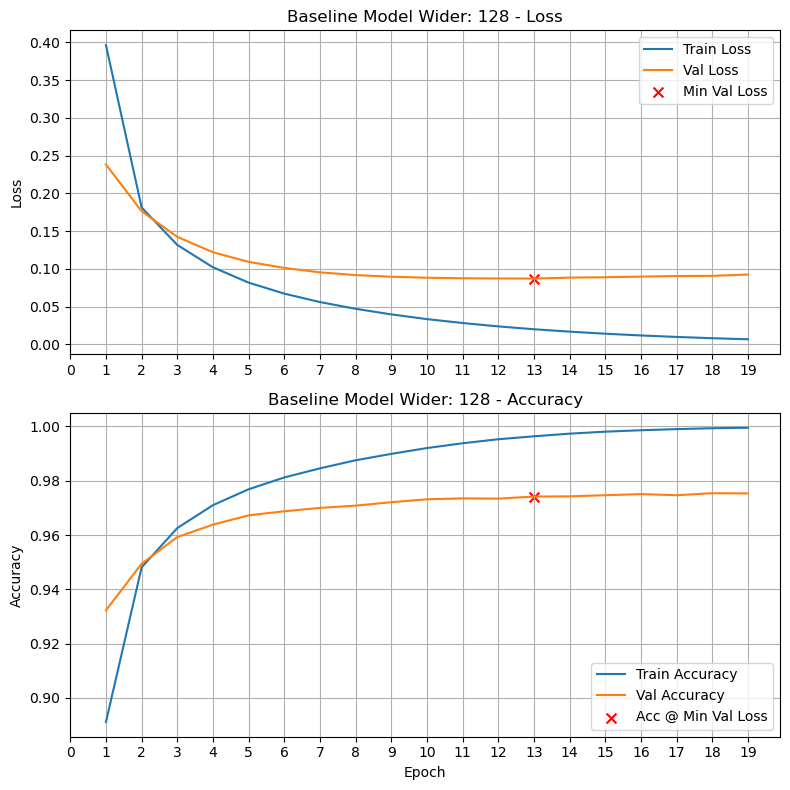

Final Training Loss:            0.0068
Final Training Accuracy:        0.9995
Final Validation Loss:          0.0926
Final Validation Accuracy:      0.9753
Minimum Validation Loss:        0.0872 (Epoch 13)
Validation Accuracy @ Min Loss: 0.9742

Epochs trained:                 19
Best validation epoch:          13
Best validation loss:           0.0872
Validation accuracy at best:    0.9742
Model weights restored from:    epoch 13
Execution time:                 00:00:11

Baseline Model Wider: 256


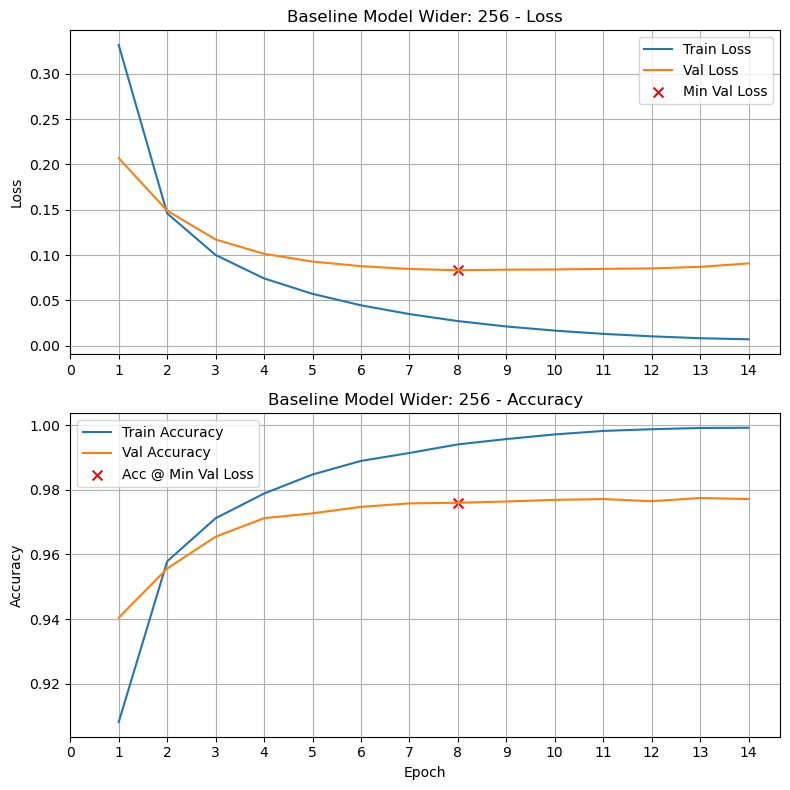

Final Training Loss:            0.0071
Final Training Accuracy:        0.9992
Final Validation Loss:          0.0909
Final Validation Accuracy:      0.9772
Minimum Validation Loss:        0.0833 (Epoch 8)
Validation Accuracy @ Min Loss: 0.9760

Epochs trained:                 14
Best validation epoch:          8
Best validation loss:           0.0833
Validation accuracy at best:    0.9760
Model weights restored from:    epoch 8
Execution time:                 00:00:12

Baseline Model Wider: 512


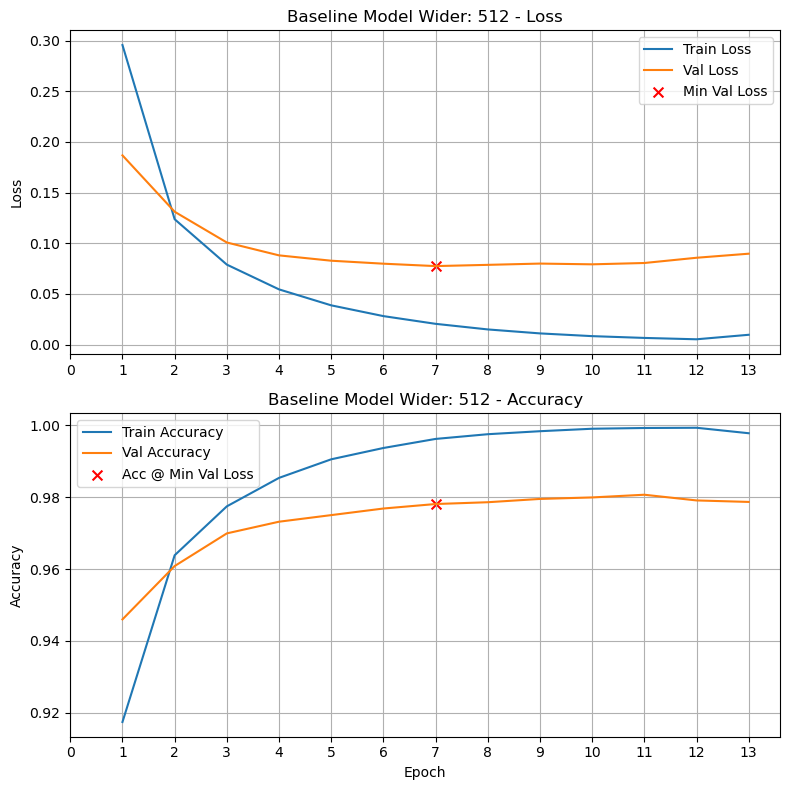

Final Training Loss:            0.0097
Final Training Accuracy:        0.9978
Final Validation Loss:          0.0897
Final Validation Accuracy:      0.9787
Minimum Validation Loss:        0.0775 (Epoch 7)
Validation Accuracy @ Min Loss: 0.9781

Epochs trained:                 13
Best validation epoch:          7
Best validation loss:           0.0775
Validation accuracy at best:    0.9781
Model weights restored from:    epoch 7
Execution time:                 00:00:16

Baseline Model Wider: 1024


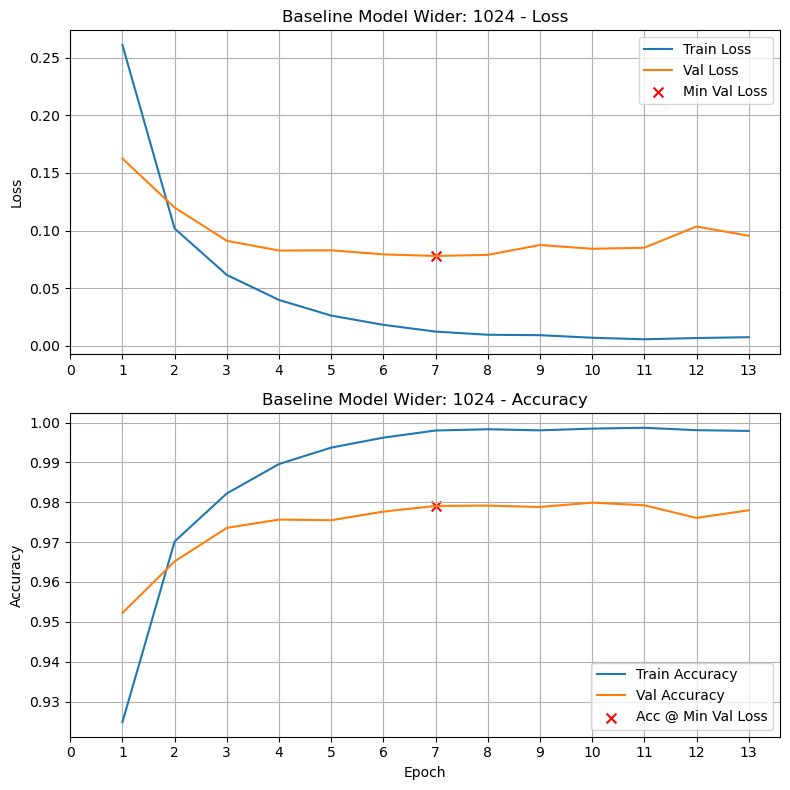

Final Training Loss:            0.0074
Final Training Accuracy:        0.9979
Final Validation Loss:          0.0954
Final Validation Accuracy:      0.9780
Minimum Validation Loss:        0.0779 (Epoch 7)
Validation Accuracy @ Min Loss: 0.9791

Epochs trained:                 13
Best validation epoch:          7
Best validation loss:           0.0779
Validation accuracy at best:    0.9791
Model weights restored from:    epoch 7
Execution time:                 00:00:23

Baseline Model Wider: 2048


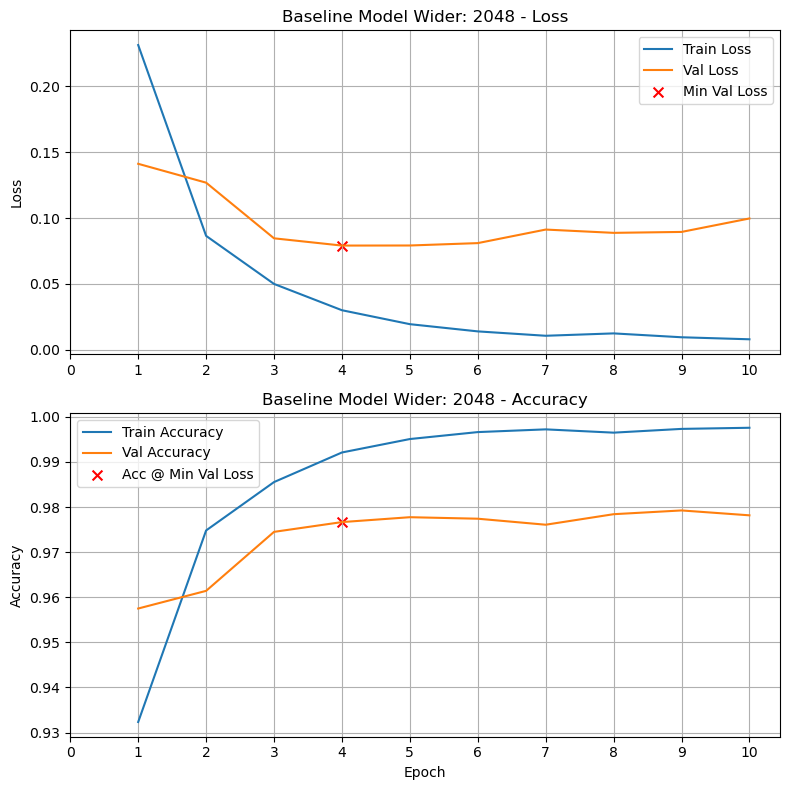

Final Training Loss:            0.0080
Final Training Accuracy:        0.9976
Final Validation Loss:          0.0996
Final Validation Accuracy:      0.9782
Minimum Validation Loss:        0.0791 (Epoch 4)
Validation Accuracy @ Min Loss: 0.9767

Epochs trained:                 10
Best validation epoch:          4
Best validation loss:           0.0791
Validation accuracy at best:    0.9767
Model weights restored from:    epoch 4
Execution time:                 00:00:25

Baseline Model Wider: 4096


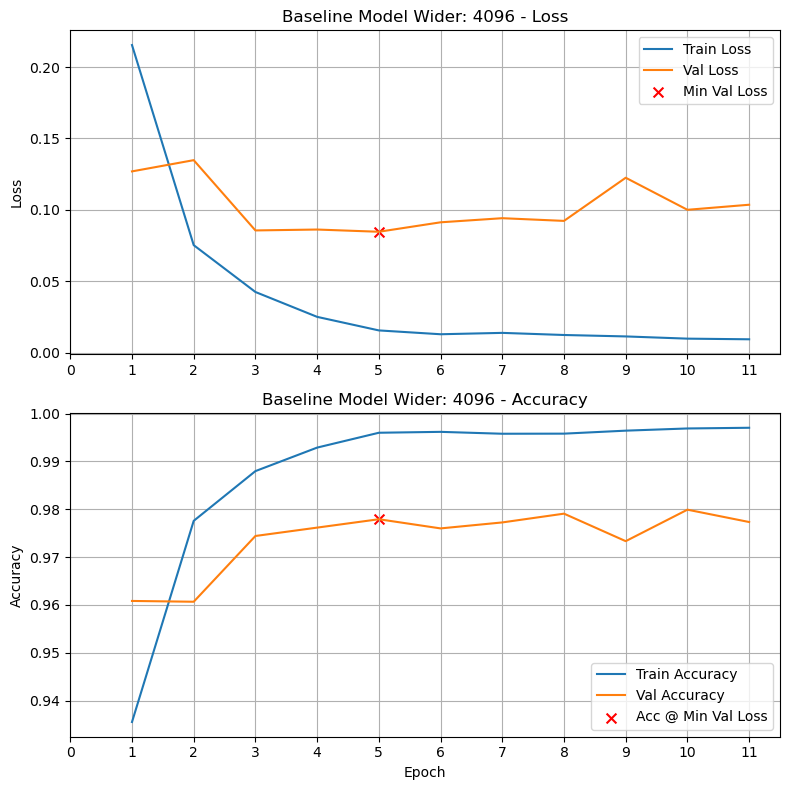

Final Training Loss:            0.0093
Final Training Accuracy:        0.9970
Final Validation Loss:          0.1035
Final Validation Accuracy:      0.9773
Minimum Validation Loss:        0.0846 (Epoch 5)
Validation Accuracy @ Min Loss: 0.9779

Epochs trained:                 11
Best validation epoch:          5
Best validation loss:           0.0846
Validation accuracy at best:    0.9779
Model weights restored from:    epoch 5
Execution time:                 00:00:30

Baseline Model Wider: 8192


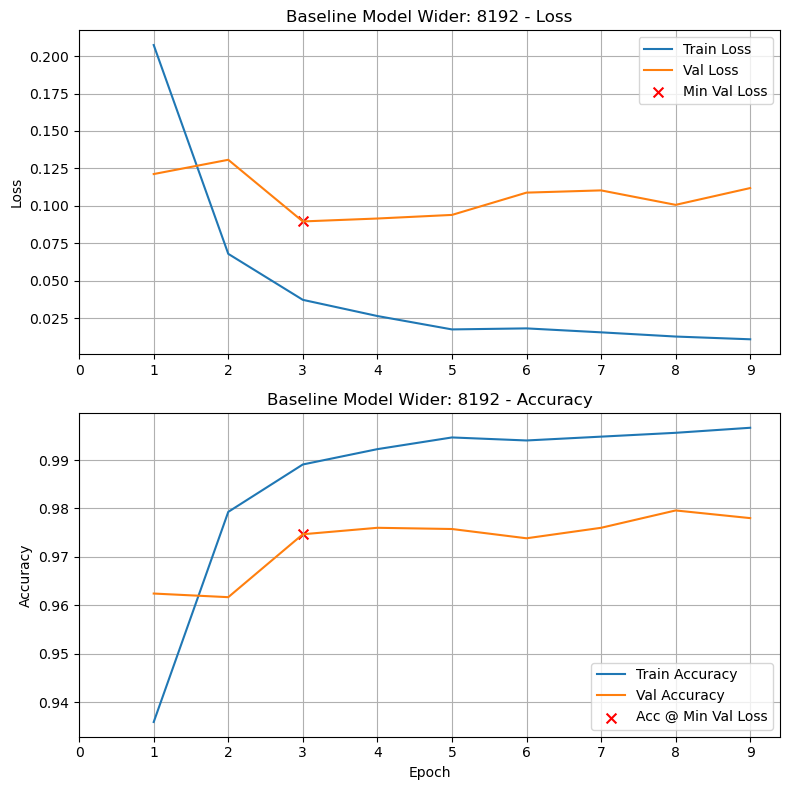

Final Training Loss:            0.0108
Final Training Accuracy:        0.9967
Final Validation Loss:          0.1118
Final Validation Accuracy:      0.9780
Minimum Validation Loss:        0.0895 (Epoch 3)
Validation Accuracy @ Min Loss: 0.9747

Epochs trained:                 9
Best validation epoch:          3
Best validation loss:           0.0895
Validation accuracy at best:    0.9747
Model weights restored from:    epoch 3
Execution time:                 00:00:45

Baseline Model Wider: 16384


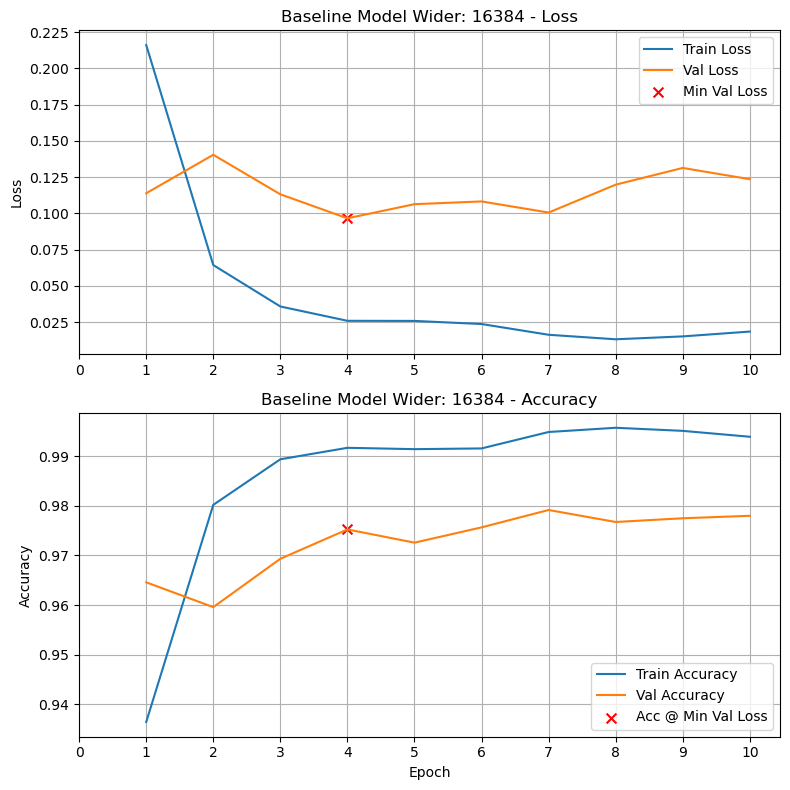

Final Training Loss:            0.0185
Final Training Accuracy:        0.9939
Final Validation Loss:          0.1236
Final Validation Accuracy:      0.9780
Minimum Validation Loss:        0.0966 (Epoch 4)
Validation Accuracy @ Min Loss: 0.9753

Epochs trained:                 10
Best validation epoch:          4
Best validation loss:           0.0966
Validation accuracy at best:    0.9753
Model weights restored from:    epoch 4
Execution time:                 00:01:48

Baseline Model Wider: 32768


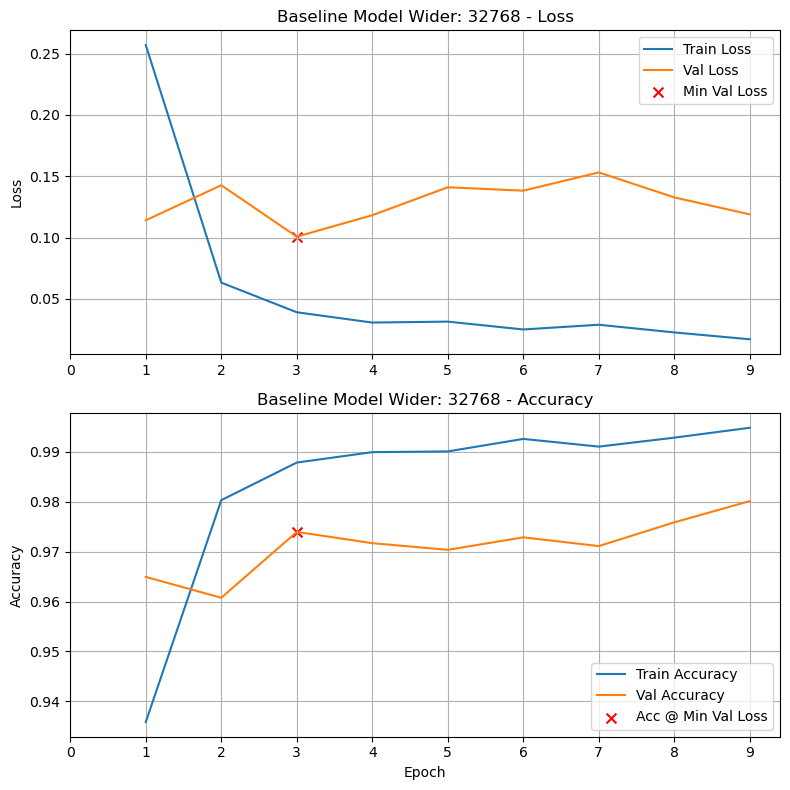

Final Training Loss:            0.0171
Final Training Accuracy:        0.9948
Final Validation Loss:          0.1189
Final Validation Accuracy:      0.9801
Minimum Validation Loss:        0.1007 (Epoch 3)
Validation Accuracy @ Min Loss: 0.9739

Epochs trained:                 9
Best validation epoch:          3
Best validation loss:           0.1007
Validation accuracy at best:    0.9739
Model weights restored from:    epoch 3
Execution time:                 00:03:07


In [30]:
for width in [2**k for k in range(4,16)]:
    base_model_wider = models.Sequential([
        Input(shape=(X_train.shape[1],)),
        Dense(
            width,
            activation="relu",
            kernel_initializer="he_uniform"
        ),
        Dense(
            num_classes,
            activation="softmax"
        )
    ])
    
    train_and_validate(
        base_model_wider,
        title=f"Baseline Model Wider: {width}",
        use_early_stopping=True,
        verbose=0
    )

### Comment:

Here are the results of this sweep over layer widths:

| Hidden-Layer Width | Validation Accuracy | Validation Loss | Best Epoch | Epochs Run |
|---:|---:|---:|---:|---:|
| 16    | 0.9516 | 0.1830 | 32 | 38 |
| 32    | 0.9652 | 0.1202 | 19 | 25 |
| 64    | 0.9709 | 0.1043 | 18 | 24 |
| 128   | 0.9742 | 0.0872 | 13 | 19 |
| 256   | 0.9760 | 0.0833 | 8  | 14 |
| 512   | 0.9781 | 0.0775 | 7  | 13 |
| 1024  | 0.9791 | 0.0779 | 7  | 13 |
| 2048  | 0.9767 | 0.0791 | 4  | 10 |
| 4096  | 0.9779 | 0.0846 | 5  | 11 |
| 8192  | 0.9747 | 0.0895 | 3  | 9  |
| 16384 | 0.9753 | 0.0966 | 4  | 10 |
| 32768 | 0.9739 | 0.1007 | 3  | 9  |

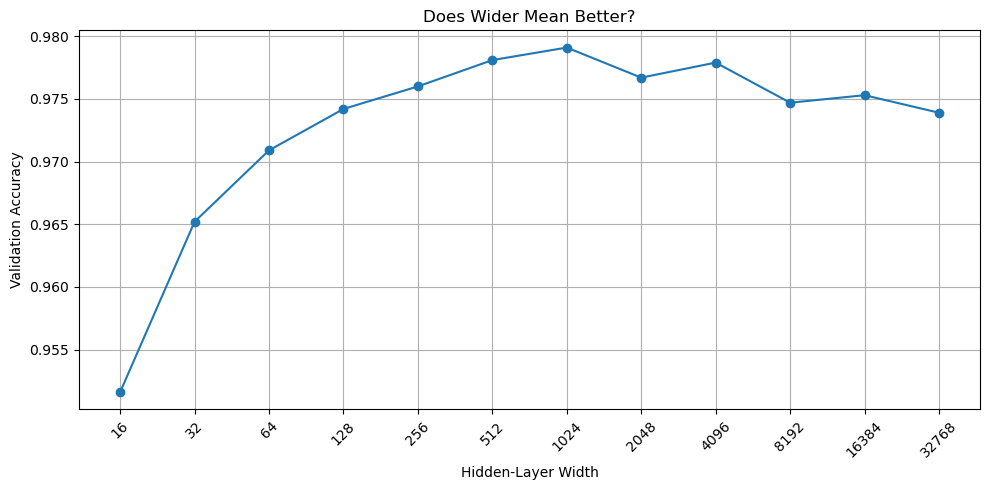

In [32]:
import matplotlib.pyplot as plt

widths = [
    16, 32, 64, 128, 256, 512,
    1024, 2048, 4096, 8192, 16384, 32768
]

val_accuracy = [
    0.9516, 0.9652, 0.9709, 0.9742, 0.9760, 0.9781,
    0.9791, 0.9767, 0.9779, 0.9747, 0.9753, 0.9739
]

plt.figure(figsize=(10, 5))

plt.plot(
    widths,
    val_accuracy,
    marker="o"
)

plt.xscale("log", base=2)

plt.xticks(widths, widths, rotation=45)

plt.xlabel("Hidden-Layer Width")
plt.ylabel("Validation Accuracy")
plt.title("Does Wider Mean Better?")

plt.grid(True)
plt.tight_layout()
plt.show()

### Conclusion: Does Wider Mean Better?

Increasing the width of the hidden layer helps substantially at first. Very small networks underfit: validation accuracy rises from **0.9516** with only 16 hidden units to about **0.979** with 1024 units.

However, the improvement does not continue indefinitely. In these experiments, validation accuracy peaks around **512–1024 units** and then generally declines as the hidden layer becomes much wider. The extremely wide networks with 8192, 16384, and 32768 units all perform worse than the much smaller 512- and 1024-unit models.

The validation loss shows a similar pattern: it improves as the network becomes wider up to roughly 512–1024 units, then begins to increase again.

Another interesting pattern is that the very wide models reach their best validation result after only a few epochs. This suggests that they have more than enough capacity to fit the training data quickly, but that additional capacity is not translating into better generalization.

The main takeaway is that **width helps only up to a point**. Too little capacity leads to underfitting, but simply adding more neurons eventually provides diminishing returns and can hurt validation performance.

Therefore, hidden-layer width should be treated as a **hyperparameter to tune**, not something to maximize.

### 7.2. Funnel: 512 → 256 → 128

Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_16 (Dense)                │ (None, 512)            │       401,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_18 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_19 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 567,434 (2.16 MB)

 Trainable params: 567,434 (2.16 MB)

 Non-trainable params: 0 (0.00 B)

None


Funnel -- 512-256-128


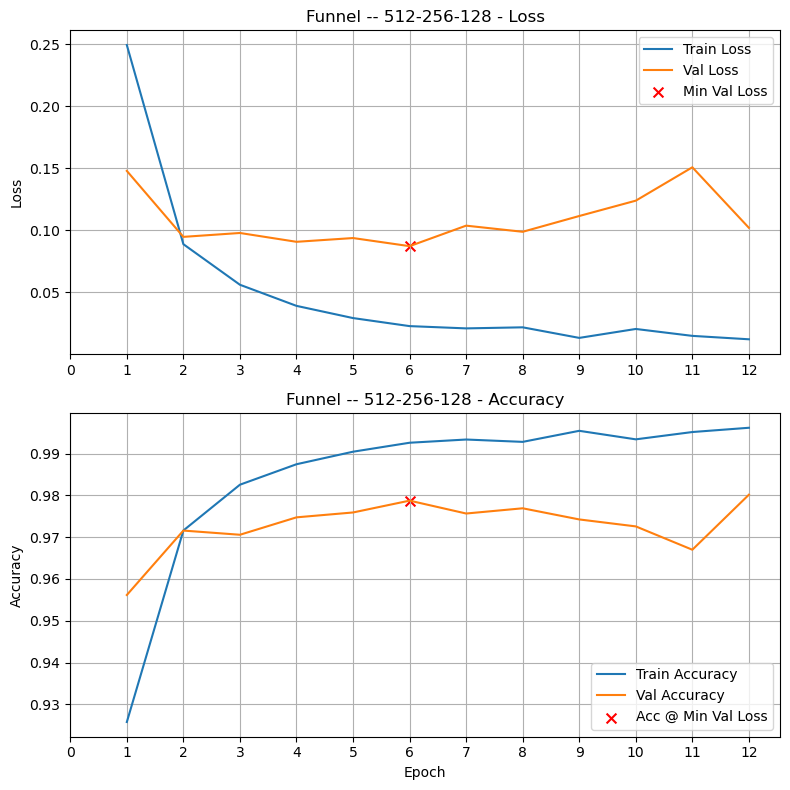

Final Training Loss:            0.0122
Final Training Accuracy:        0.9962
Final Validation Loss:          0.1020
Final Validation Accuracy:      0.9802
Minimum Validation Loss:        0.0873 (Epoch 6)
Validation Accuracy @ Min Loss: 0.9787

Epochs trained:                 12
Best validation epoch:          6
Best validation loss:           0.0873
Validation accuracy at best:    0.9787
Model weights restored from:    epoch 6
Execution time:                 00:00:29


In [15]:
funnel_model = models.Sequential([
    Input(shape=(X_train.shape[1],)),

    Dense(
        512,
        activation="relu",
        kernel_initializer="he_uniform"
    ),
    Dense(
        256,
        activation="relu",
        kernel_initializer="he_uniform"
    ),

    Dense(
        128,
        activation="relu",
        kernel_initializer="he_uniform"
    ),

    Dense(
        num_classes,
        activation="softmax"
    )
])

display(funnel_model.summary())

train_and_validate(
    funnel_model,
    title="Funnel -- 512-256-128",
    verbose=0
)

### 7.3. Diamond: 128 → 256 → 128

Model: "sequential_9"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_20 (Dense)                │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_21 (Dense)                │ (None, 256)            │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_22 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_23 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 167,690 (655.04 KB)

 Trainable params: 167,690 (655.04 KB)

 Non-trainable params: 0 (0.00 B)

None


Diamond Model -- 128-256-128


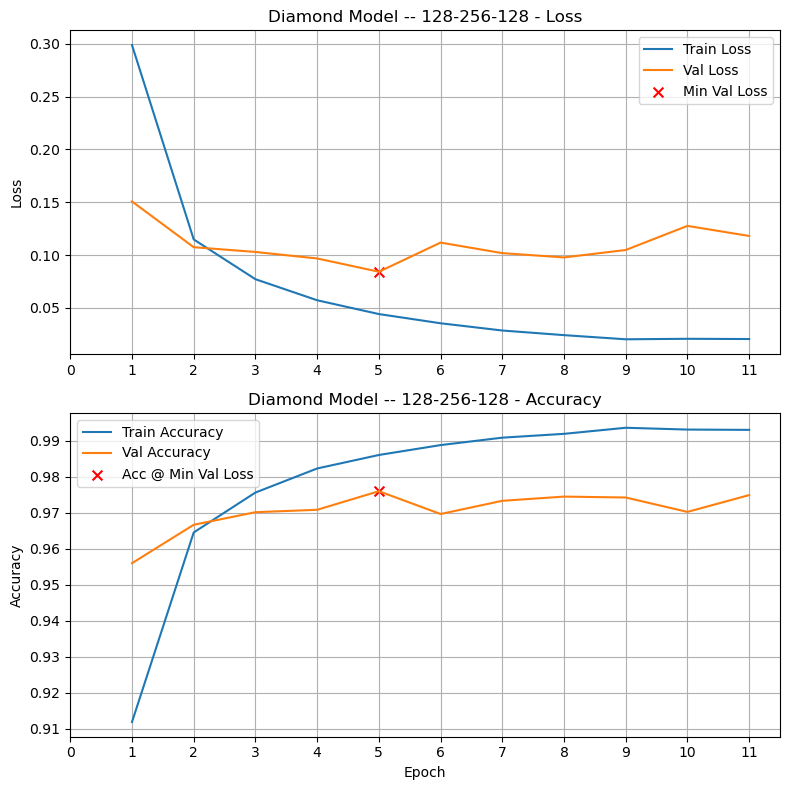

Final Training Loss:            0.0204
Final Training Accuracy:        0.9930
Final Validation Loss:          0.1181
Final Validation Accuracy:      0.9749
Minimum Validation Loss:        0.0841 (Epoch 5)
Validation Accuracy @ Min Loss: 0.9760

Epochs trained:                 11
Best validation epoch:          5
Best validation loss:           0.0841
Validation accuracy at best:    0.9760
Model weights restored from:    epoch 5
Execution time:                 00:00:13


In [16]:
diamond_model = models.Sequential([
    Input(shape=(X_train.shape[1],)),

    Dense(
        128,
        activation="relu",
        kernel_initializer="he_uniform"
    ),
    Dense(
        256,
        activation="relu",
        kernel_initializer="he_uniform"
    ),
    Dense(
        128,
        activation="relu",
        kernel_initializer="he_uniform"
    ),

    Dense(
        num_classes,
        activation="softmax"
    )
])

display(diamond_model.summary())

train_and_validate(
    diamond_model,
    title="Diamond Model -- 128-256-128",
    verbose=0
)

### 7.4. Constant Width: 512 → 512

Model: "sequential_10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_24 (Dense)                │ (None, 512)            │       401,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_25 (Dense)                │ (None, 512)            │       262,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_26 (Dense)                │ (None, 10)             │         5,130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 669,706 (2.55 MB)

 Trainable params: 669,706 (2.55 MB)

 Non-trainable params: 0 (0.00 B)

None


Constant Width Model -- 512-512


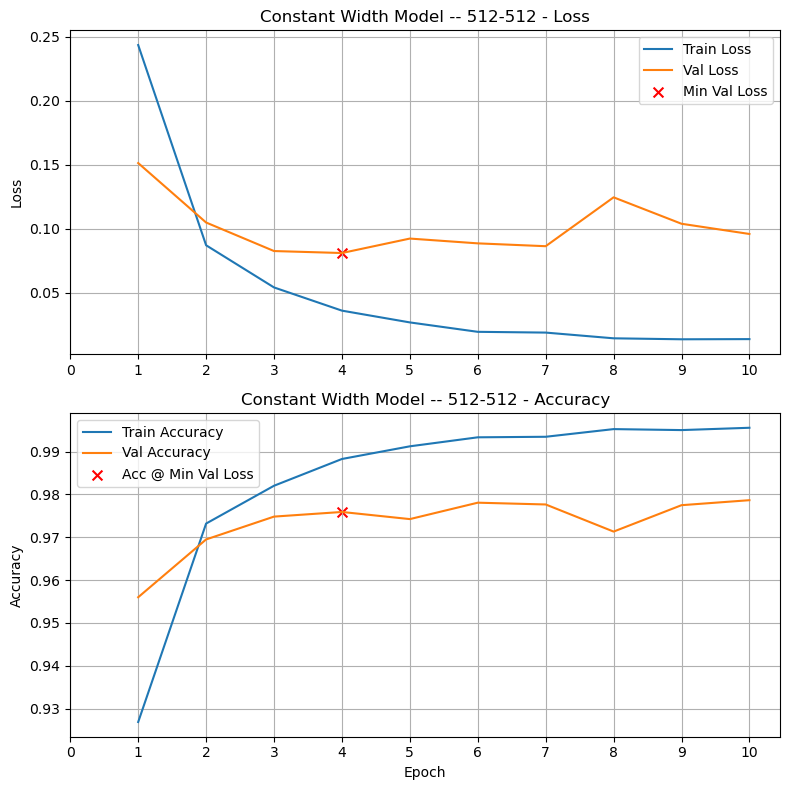

Final Training Loss:            0.0139
Final Training Accuracy:        0.9956
Final Validation Loss:          0.0961
Final Validation Accuracy:      0.9787
Minimum Validation Loss:        0.0812 (Epoch 4)
Validation Accuracy @ Min Loss: 0.9759

Epochs trained:                 10
Best validation epoch:          4
Best validation loss:           0.0812
Validation accuracy at best:    0.9759
Model weights restored from:    epoch 4
Execution time:                 00:00:21


In [17]:
wide_model = models.Sequential([
    Input(shape=(X_train.shape[1],)),

    Dense(
        512,
        activation="relu",
        kernel_initializer="he_uniform"
    ),
    Dense(
        512,
        activation="relu",
        kernel_initializer="he_uniform"
    ),
    Dense(
        num_classes,
        activation="softmax"
    )
])

display(wide_model.summary())

train_and_validate(
    wide_model,
    title="Constant Width Model -- 512-512",
    verbose=0
)

### 7.5. Funnel with BatchNorm, L2, and Dropout

Model: "sequential_11"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_27 (Dense)                │ (None, 512)            │       401,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_28 (Dense)                │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_29 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_3 (ReLU)                  │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_30 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 571,018 (2.18 MB)

 Trainable params: 569,226 (2.17 MB)

 Non-trainable params: 1,792 (7.00 KB)

None


Funnel 512-256-128 with BN+L2+Dropout


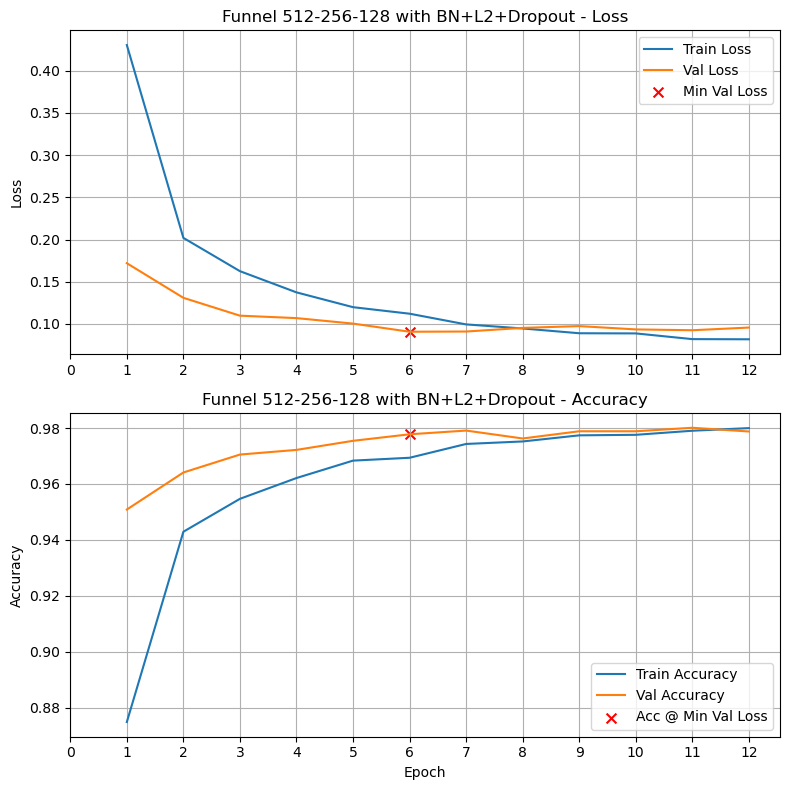

Final Training Loss:            0.0819
Final Training Accuracy:        0.9800
Final Validation Loss:          0.0958
Final Validation Accuracy:      0.9787
Minimum Validation Loss:        0.0908 (Epoch 6)
Validation Accuracy @ Min Loss: 0.9778

Epochs trained:                 12
Best validation epoch:          6
Best validation loss:           0.0908
Validation accuracy at best:    0.9778
Model weights restored from:    epoch 6
Execution time:                 00:00:40


In [18]:


funnel_model2 = models.Sequential([
    Input(shape=(X_train.shape[1],)),

    Dense(
        512,
        kernel_initializer="he_uniform",
        kernel_regularizer=regularizers.l2(1e-5)
    ),
    BatchNormalization(),
    ReLU(),
    Dropout(0.4),

    Dense(
        256,
        kernel_initializer="he_uniform",
        kernel_regularizer=regularizers.l2(1e-5)
    ),
    BatchNormalization(),
    ReLU(),
    Dropout(0.3),

    Dense(
        128,
        kernel_initializer="he_uniform",
        kernel_regularizer=regularizers.l2(1e-6)
    ),
    BatchNormalization(),
    ReLU(),
    Dropout(0.2),

    Dense(
        num_classes,
        activation="softmax"
    )
])

display(funnel_model2.summary())

train_and_validate(
    funnel_model2,
    # learning_rate = 1e-4,
    title="Funnel 512-256-128 with BN+L2+Dropout",
    verbose=0
)

### 7.6. Funnel with BatchNorm, L2, and Dropout trained using Reduce LR on Plateau

Model: "sequential_12"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_31 (Dense)                │ (None, 512)            │       401,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_4 (ReLU)                  │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_32 (Dense)                │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_5 (ReLU)                  │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_33 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_6 (ReLU)                  │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_34 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 571,018 (2.18 MB)

 Trainable params: 569,226 (2.17 MB)

 Non-trainable params: 1,792 (7.00 KB)

None


Funnel 512-256-128 with BN+L2+DO + RLR

Epoch 13: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.

Epoch 17: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.

Epoch 21: ReduceLROnPlateau reducing learning rate to 0.0001250000059371814.

Epoch 24: ReduceLROnPlateau reducing learning rate to 6.25000029685907e-05.


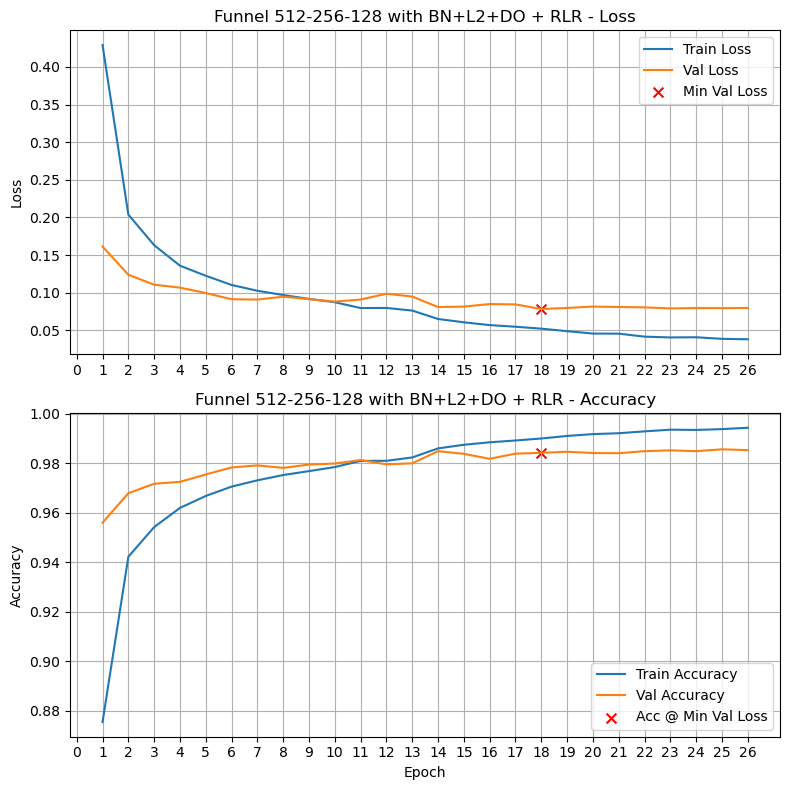

Final Training Loss:            0.0381
Final Training Accuracy:        0.9944
Final Validation Loss:          0.0797
Final Validation Accuracy:      0.9853
Minimum Validation Loss:        0.0783 (Epoch 18)
Validation Accuracy @ Min Loss: 0.9843

Epochs trained:                 26
Best validation epoch:          18
Best validation loss:           0.0783
Validation accuracy at best:    0.9843
Model weights restored from:    epoch 18
Execution time:                 00:01:23


In [19]:
from tensorflow.keras.callbacks import ReduceLROnPlateau



funnel_model2 = models.Sequential([
    Input(shape=(X_train.shape[1],)),

    Dense(
        512,
        kernel_initializer="he_uniform",
        kernel_regularizer=regularizers.l2(1e-5)
    ),
    BatchNormalization(),
    ReLU(),
    Dropout(0.4),

    Dense(
        256,
        kernel_initializer="he_uniform",
        kernel_regularizer=regularizers.l2(1e-5)
    ),
    BatchNormalization(),
    ReLU(),
    Dropout(0.3),

    Dense(
        128,
        kernel_initializer="he_uniform",
        kernel_regularizer=regularizers.l2(1e-6)
    ),
    BatchNormalization(),
    ReLU(),
    Dropout(0.2),

    Dense(
        num_classes,
        activation="softmax"
    )
])

display(funnel_model2.summary())

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=3,
    min_lr=1e-6,
    verbose=1
)

train_and_validate(
    funnel_model2,
    title="Funnel 512-256-128 with BN+L2+DO + RLR",
    patience=8,
    extra_callbacks=[reduce_lr],
    verbose=0
)

### 7.7. Funnel with BatchNorm, L2, and Dropout trained using Exponential Decay

Model: "sequential_13"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_35 (Dense)                │ (None, 512)            │       401,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_7 (ReLU)                  │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_36 (Dense)                │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_8 (ReLU)                  │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_37 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_9 (ReLU)                  │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_38 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 571,018 (2.18 MB)

 Trainable params: 569,226 (2.17 MB)

 Non-trainable params: 1,792 (7.00 KB)

None


Funnel 512-256-128 with BN+L2+DO + Exp


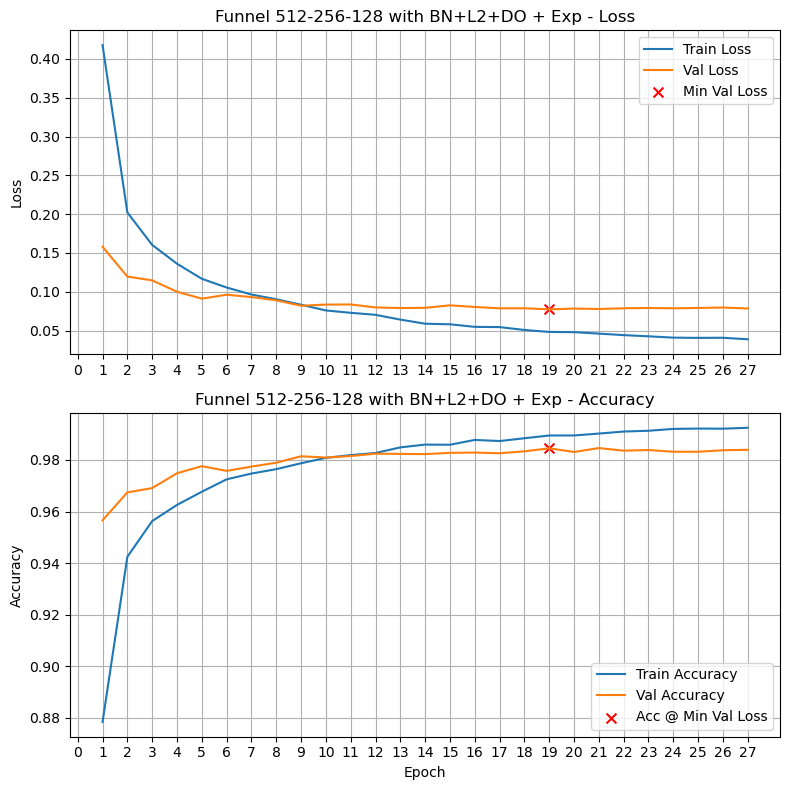

Final Training Loss:            0.0388
Final Training Accuracy:        0.9925
Final Validation Loss:          0.0785
Final Validation Accuracy:      0.9839
Minimum Validation Loss:        0.0774 (Epoch 19)
Validation Accuracy @ Min Loss: 0.9845

Epochs trained:                 27
Best validation epoch:          19
Best validation loss:           0.0774
Validation accuracy at best:    0.9845
Model weights restored from:    epoch 19
Execution time:                 00:01:28


In [20]:

steps_per_epoch = math.ceil(len(X_train) / batch_size)

exp_lr = tf.keras.optimizers.schedules.ExponentialDecay(
    initial_learning_rate=1e-3,
    decay_steps=steps_per_epoch * 10,  # halve about every 10 epochs
    decay_rate=0.5,
    staircase=False
)

funnel_model3 = models.Sequential([
    Input(shape=(X_train.shape[1],)),

    Dense(
        512,
        kernel_initializer="he_uniform",
        kernel_regularizer=regularizers.l2(1e-5)
    ),
    BatchNormalization(),
    ReLU(),
    Dropout(0.4),

    Dense(
        256,
        kernel_initializer="he_uniform",
        kernel_regularizer=regularizers.l2(1e-5)
    ),
    BatchNormalization(),
    ReLU(),
    Dropout(0.3),

    Dense(
        128,
        kernel_initializer="he_uniform",
        kernel_regularizer=regularizers.l2(1e-6)
    ),
    BatchNormalization(),
    ReLU(),
    Dropout(0.2),

    Dense(
        num_classes,
        activation="softmax"
    )
])

display(funnel_model3.summary())

train_and_validate(
    funnel_model3,
    learning_rate=exp_lr,
    title="Funnel 512-256-128 with BN+L2+DO + Exp",
    patience=8,
    verbose=0
)

### Comparison of All Models

In [31]:
# Print results sorted by accuracy (highest → lowest)
print_results()

Model                                       Val Acc   Val Loss   Best Epoch   Epochs Run
------------------------------------------------------------------------------------------
Funnel 512-256-128 with BN+L2+DO + Exp       0.9845     0.0774           19           27
Funnel 512-256-128 with BN+L2+DO + RLR       0.9843     0.0783           18           26
Baseline Model -- L2 1e-05 & DO 0.3          0.9811     0.0859           11           17
ReLU + L2 Regularization  1e-05              0.9800     0.0874            7           13
Baseline Model -- ReLU                       0.9798     0.0733            8           14
ReLU + Dropout 0.3                           0.9793     0.0697            7           13
Baseline Model Wider: 1024                   0.9791     0.0779            7           13
Baseline Model                               0.9789     0.0753           20          100
Funnel -- 512-256-128                        0.9787     0.0873            6           12
Baseline Model Wide

## Run on the Test Set

We have now finished using the validation set to make modeling decisions. We compared different architectures, regularization methods, and learning-rate strategies, and used validation performance to decide which configuration to carry forward.

As our final step, we select the **best-performing model from these experiments**. In this run, that is the **Funnel 512-256-128 network with Batch Normalization, L2 regularization, Dropout, and Exponential Learning-Rate Decay**. The model using **ReduceLROnPlateau** performed almost as well.

An important takeaway from these experiments is that **managing the learning rate during training provided a noticeable improvement in validation performance**. Both learning-rate strategies performed very well, suggesting that allowing the learning rate to decrease as training progresses can help the network make larger updates early in training and finer adjustments as it approaches a good solution.

Here, “best-performing” means that this model achieved the highest validation accuracy among the models we tested. It does not mean that this architecture or learning-rate strategy is universally optimal.

The test set has remained untouched during this entire model-selection process. We now rebuild the selected model, train it on the complete **development set (Train + Validation)**, and evaluate it once on the test set to obtain our final estimate of performance on unseen data.

For the final model:

1. Rebuild the selected network from scratch.
2. Train it on the complete **development set** (`Train + Validation`).
3. Use the number of training epochs selected during validation rather than using early stopping again.
4. Recreate the selected exponential learning-rate schedule for the larger development set.
5. Evaluate the final model **once** on the test set.

This gives the final test result for the model-selection process without using the test set to influence any modeling decisions.

In [23]:
# ==================================================
# Final Model: Refit on Development Set and Test Once
# ==================================================

# Number of epochs selected during validation
best_epochs = results[
    "Funnel 512-256-128 with BN+L2+DO + Exp"
]["best_epoch"]

print(f"Training final model for {best_epochs} epochs")

# --------------------------------------------------
# Recreate the exponential learning-rate schedule
#
# Recalculate steps_per_epoch because the final model
# is trained on the larger Development set.
# --------------------------------------------------

steps_per_epoch = math.ceil(len(X_development) / batch_size)

exp_lr_final = tf.keras.optimizers.schedules.ExponentialDecay(
    initial_learning_rate=1e-3,
    decay_steps=steps_per_epoch * 10,
    decay_rate=0.5,
    staircase=False
)

# --------------------------------------------------
# Build a fresh copy of the selected architecture
# --------------------------------------------------

tf.keras.utils.set_random_seed(42)

final_model = models.Sequential([
    Input(shape=(X_development.shape[1],)),

    Dense(
        512,
        kernel_initializer="he_uniform",
        kernel_regularizer=regularizers.l2(1e-5)
    ),
    BatchNormalization(),
    ReLU(),
    Dropout(0.4),

    Dense(
        256,
        kernel_initializer="he_uniform",
        kernel_regularizer=regularizers.l2(1e-5)
    ),
    BatchNormalization(),
    ReLU(),
    Dropout(0.3),

    Dense(
        128,
        kernel_initializer="he_uniform",
        kernel_regularizer=regularizers.l2(1e-6)
    ),
    BatchNormalization(),
    ReLU(),
    Dropout(0.2),

    Dense(
        num_classes,
        activation="softmax"
    )
])

# --------------------------------------------------
# Compile
# --------------------------------------------------

final_model.compile(
    optimizer=Adam(learning_rate=exp_lr_final),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# --------------------------------------------------
# Refit on the complete Development set
# --------------------------------------------------

final_model.fit(
    X_development,
    y_development,
    epochs=best_epochs,
    batch_size=batch_size,
    verbose=0
)

# --------------------------------------------------
# Final evaluation on untouched Test set
# --------------------------------------------------

test_loss, test_accuracy = final_model.evaluate(
    X_test,
    y_test,
    verbose=0
)

print("\nFinal Test Results")
print(f"Test loss:     {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")

Training final model for 19 epochs

Final Test Results
Test loss:     0.0749
Test accuracy: 0.9836


## Conclusion

These experiments illustrate several important lessons about improving neural-network training:

- **More layers or more neurons do not automatically produce a better model.**  
  The Funnel, Diamond, and Constant-Width architectures did not outperform the simpler baseline models by themselves. Architecture is only one part of the training process.

- **Regularization can improve generalization.**  
  L2 regularization and Dropout were each useful, but using them together produced the strongest result among the simpler models. This suggests that the two methods can complement one another: L2 discourages excessively large weights, while Dropout discourages the network from relying too heavily on particular neurons.

- **Batch Normalization becomes more useful as networks become deeper.**  
  In our simpler models, Batch Normalization alone did not noticeably improve validation accuracy. However, in deeper networks it can help stabilize the activations passed from one layer to the next and make optimization easier. Its benefit may therefore be more apparent when it is used as part of a deeper architecture rather than as an isolated change to a shallow network.

- **Learning-rate management produced the largest improvement.**  
  The two best validation accuracies came from the same regularized Funnel architecture using either **Exponential Decay** or **ReduceLROnPlateau**. Their results were extremely close, suggesting that the important lesson is not that one schedule is always better, but that **reducing the learning rate as training progresses can significantly improve the final solution**.

- **Early stopping is valuable even when it does not improve accuracy.**  
  The baseline model trained for all 100 epochs, while early stopping terminated training much sooner. This illustrates that early stopping can reduce unnecessary computation and protect against later overfitting.

- **No single technique guarantees improvement.**  
  Some changes produced only small gains, and some combinations performed worse than simpler models. Neural-network design is therefore an experimental process: make one or a few controlled changes, evaluate them on validation data, and keep the changes that improve the desired metric.

Overall, the strongest result came from combining a reasonable multilayer architecture with **Batch Normalization, L2 regularization, Dropout, and learning-rate scheduling**. The larger lesson, however, is that good neural-network performance depends not just on architecture, but on the entire **training strategy**.

### Appendix: Recommended Callbacks


| Callback                  | What It Does                                                | Why Use It                                            |
|---------------------------|-------------------------------------------------------------|--------------------------------------------------------|
| **`EarlyStopping`**       | Stops training when validation performance stops improving  | Prevents overfitting; saves time                      |
| **`ModelCheckpoint`**     | Saves the model to disk during training                     | Keeps the best version of your model                  |
| **`ReduceLROnPlateau`**   | Lowers learning rate when validation loss plateaus          | Helps model continue improving when stuck             |
| **`TensorBoard`**         | Logs training progress for interactive visualization        | Lets you inspect loss, accuracy, etc. over time       |
| **`CSVLogger`**           | Saves loss and metric history to a CSV file                 | Easy to analyze training results in Excel or Pandas   |
| **`LearningRateScheduler`** | Manually adjust learning rate schedule per epoch         | For advanced tuning or warm-up strategies             |



#### Example: Combining multiple callbacks

```python
callbacks_list = [
    tf.keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True),
    tf.keras.callbacks.ModelCheckpoint("best_model.h5", save_best_only=True),
    tf.keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=2)
]

model.fit(
    X_train, y_train,
    validation_split=0.2,
    epochs=50,
    callbacks=callbacks_list
)
```



In [ ]:
import tensorflow as tf

# Check for available GPU
print("Available GPU:", tf.config.list_physical_devices('GPU'))

# Optional: Show where a tensor is stored
tensor = tf.constant([[1.0, 2.0], [3.0, 4.0]])
print("Tensor is on device:", tensor.device)

### Moving a Tensor Between CPU and GPU

In most cases, **you won’t need to move tensors manually** — when you use Keras to define and train models, TensorFlow automatically places operations on the GPU (in Colab or on your local machine) if one is available.

However, it’s helpful to understand how TensorFlow manages devices and how to **explicitly place tensors or operations on the CPU or GPU**, especially when debugging or optimizing more complex workflows. This is more common when working with **lower-level TensorFlow code** rather than the high-level Keras API.

For example, you can write:

```python
with tf.device('/GPU:0'):
    a = tf.constant([[1.0, 2.0]])
```

Or move a tensor back to the CPU explicitly:

```python
with tf.device('/CPU:0'):
    b = tf.identity(a)
```

These techniques are useful if you're profiling performance, mixing device types, or encountering device placement errors.



In [ ]:
'''
import tensorflow as tf

# Create a tensor on the CPU (default)
with tf.device('/CPU:0'):
    cpu_tensor = tf.constant([[1.0, 2.0], [3.0, 4.0]])
    print("Created on:", cpu_tensor.device)

# Move tensor to GPU (if available)
if tf.config.list_physical_devices('GPU'):
    with tf.device('/GPU:0'):
        gpu_tensor = tf.identity(cpu_tensor)
        print("Moved to:", gpu_tensor.device)

    # Move back to CPU
    with tf.device('/CPU:0'):
        back_to_cpu = tf.identity(gpu_tensor)
        print("Moved back to:", back_to_cpu.device)
else:
    print("No GPU available – skipping GPU transfer.")
'''
